Before running this section, write in your own words: where you obtained this dataset, what one row represents, and what this first inspection is intended to establish.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_curve,
    auc,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.svm import SVC, SVR
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
DATA_PATH = Path("PRSA_data_2010.1.1-2014.12.31.csv")
raw = pd.read_csv(DATA_PATH, na_values=["NA"])

print(f"Shape: {raw.shape}")
display(raw.dtypes.to_frame("dtype"))
display(raw.describe(include="all").T)
raw.head()

Shape: (43824, 13)


,dtype
No,int64
year,int64
month,int64
day,int64
hour,int64
pm2.5,float64
DEWP,int64
TEMP,float64
PRES,float64
cbwd,object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
No,43824.0,NaN,NaN,NaN,21912.5,12651.043435,1.0,10956.75,21912.5,32868.25,43824.0
year,43824.0,NaN,NaN,NaN,2012.0,1.413842,2010.0,2011.0,2012.0,2013.0,2014.0
month,43824.0,NaN,NaN,NaN,6.523549,3.448572,1.0,4.0,7.0,10.0,12.0
day,43824.0,NaN,NaN,NaN,15.72782,8.799425,1.0,8.0,16.0,23.0,31.0
hour,43824.0,NaN,NaN,NaN,11.5,6.922266,0.0,5.75,11.5,17.25,23.0
pm2.5,41757.0,NaN,NaN,NaN,98.613215,92.050387,0.0,29.0,72.0,137.0,994.0
DEWP,43824.0,NaN,NaN,NaN,1.817246,14.43344,-40.0,-10.0,2.0,15.0,28.0
TEMP,43824.0,NaN,NaN,NaN,12.448521,12.198613,-19.0,2.0,14.0,23.0,42.0
PRES,43824.0,NaN,NaN,NaN,1016.447654,10.268698,991.0,1008.0,1016.0,1025.0,1046.0
cbwd,43824,4,SE,15290,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


Before running this section, explain why a proper hourly datetime index matters. In your own words, interpret the timestamp checks and missing-target run lengths printed below, and justify the short-gap rule you choose.

In [2]:
df = raw.copy()
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("datetime").set_index("datetime")

print("Duplicate timestamps:", df.index.duplicated().sum())
print("Missing hourly timestamps:", len(pd.date_range(df.index.min(), df.index.max(), freq="h").difference(df.index)))
print("Missing values by column:")
display(df.isna().sum().to_frame("missing"))

missing_mask = df["pm2.5"].isna()
run_ids = missing_mask.ne(missing_mask.shift()).cumsum()
missing_runs = (
    df.loc[missing_mask].groupby(run_ids[missing_mask]).size()
    .value_counts().sort_index().rename_axis("gap_hours").to_frame("number_of_gaps")
)
display(missing_runs)

# Physical validity checks and consecutive identical-value runs.
print("Negative PM2.5 readings:", int((df["pm2.5"] < 0).sum()))
print("Negative wind speeds:", int((df["Iws"] < 0).sum()))
print("Negative snow/rain counters:", int(((df[["Is", "Ir"]] < 0).any(axis=1)).sum()))
for column in ["pm2.5", "DEWP", "TEMP", "PRES", "Iws"]:
    same_as_previous = df[column].eq(df[column].shift()) & df[column].notna()
    streak_id = (~same_as_previous).cumsum()
    longest = int(same_as_previous.groupby(streak_id).sum().max()) + 1 if same_as_previous.any() else 1
    print(f"Longest repeated {column} reading: {longest} hours")

Duplicate timestamps: 0
Missing hourly timestamps: 0
Missing values by column:


,missing
No,0
year,0
month,0
day,0
hour,0
pm2.5,2067
DEWP,0
TEMP,0
PRES,0
cbwd,0


,number_of_gaps
gap_hours,
1,112
2,29
3,2
4,5
5,6
6,4
7,6
8,3
9,6


Negative PM2.5 readings: 0
Negative wind speeds: 0
Negative snow/rain counters: 0
Longest repeated pm2.5 reading: 4 hours
Longest repeated DEWP reading: 49 hours
Longest repeated TEMP reading: 49 hours
Longest repeated PRES reading: 48 hours
Longest repeated Iws reading: 9 hours


Before running this section, explain why you will not replace missing target values with a global average. Choose a maximum interpolation gap that you can defend from the run-length table; the example below uses three hours and retains longer gaps as missing.

In [3]:
MAX_INTERPOLATION_GAP = 3

df["pm2.5_original"] = df["pm2.5"]
df["pm2.5"] = df["pm2.5"].interpolate(
    method="time", limit=MAX_INTERPOLATION_GAP, limit_area="inside"
)
print("Remaining missing PM2.5 values:", int(df["pm2.5"].isna().sum()))
print("Short-gap values interpolated:", int((df["pm2.5_original"].isna() & df["pm2.5"].notna()).sum()))

# Preserve extreme values for investigation; do not trim them automatically.
q1, q3 = df["pm2.5"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
print("IQR upper fence:", upper_fence)
print("Readings above upper fence:", int((df["pm2.5"] > upper_fence).sum()))
print("Maximum PM2.5:", df["pm2.5"].max())
display(df.loc[df["pm2.5"] > upper_fence, ["pm2.5", "TEMP", "DEWP", "PRES", "cbwd", "Iws"]].head(10))

Remaining missing PM2.5 values: 1681
Short-gap values interpolated: 386
IQR upper fence: 299.0
Readings above upper fence: 1785
Maximum PM2.5: 994.0


,pm2.5,TEMP,DEWP,PRES,cbwd,Iws
datetime,,,,,,
2010-01-17 21:00:00,317.0,-7.0,-10,1027.0,cv,0.90
2010-01-17 23:00:00,313.0,-9.0,-12,1027.0,NE,0.89
2010-01-18 02:00:00,303.0,-9.0,-11,1028.0,NW,4.92
2010-01-18 03:00:00,349.0,-10.0,-13,1028.0,NW,6.71
2010-01-18 04:00:00,407.0,-11.0,-13,1028.0,NW,7.60
2010-01-18 05:00:00,361.0,-11.0,-13,1027.0,NE,1.79
2010-01-18 19:00:00,408.0,-3.0,-7,1025.0,SE,0.89
2010-01-18 20:00:00,435.0,-2.0,-5,1026.0,cv,0.89
2010-01-18 21:00:00,403.0,-1.0,-5,1026.0,NW,1.79


Before you run these figures, predict what the raw and log-scale target distributions may look like. Afterward, write your own short interpretation of each of the four plots, including one consequence for modeling.

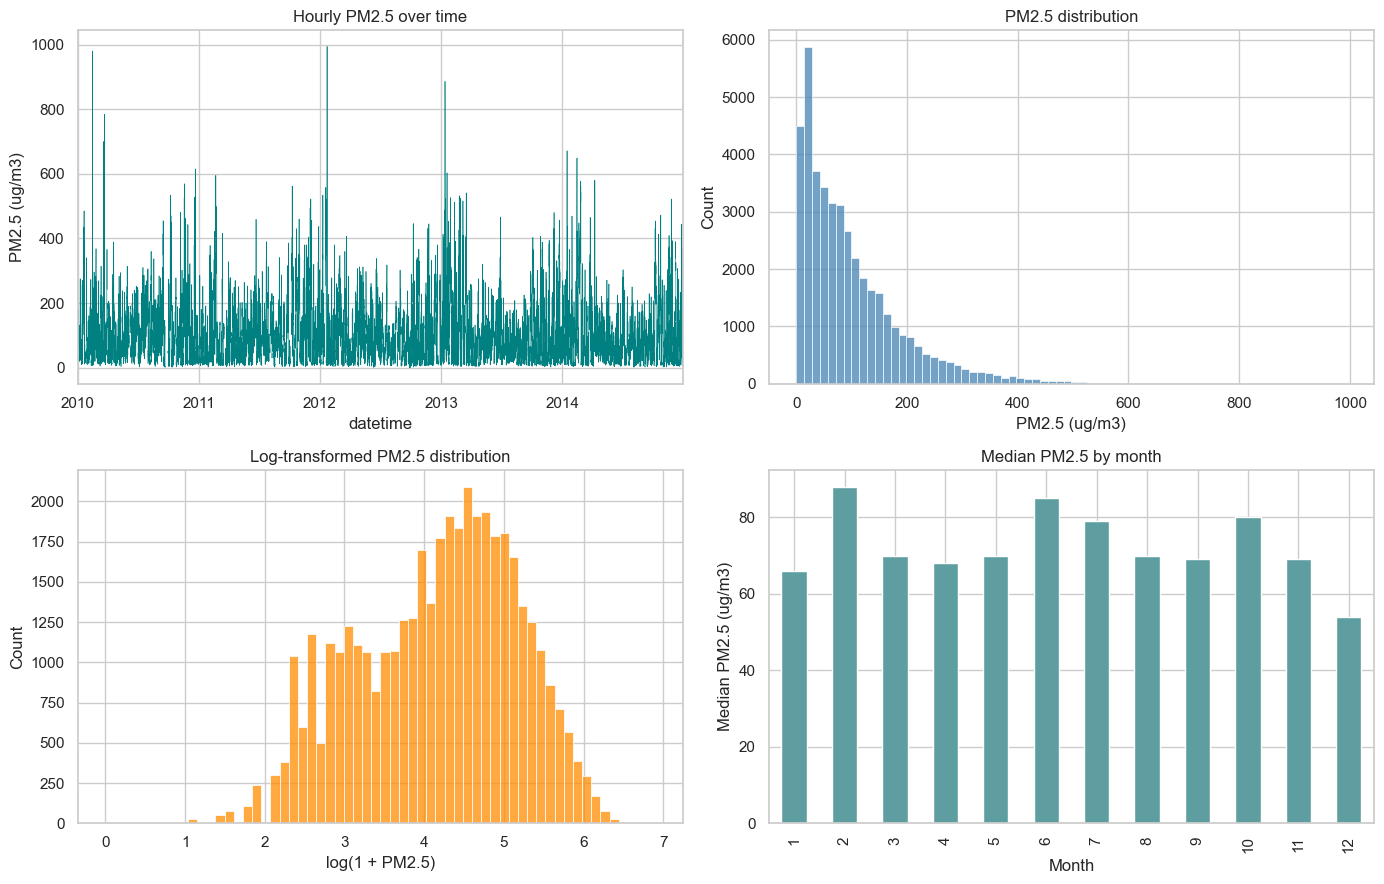

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Plot 1: full series, to expose seasonal structure and spikes.
df["pm2.5"].plot(ax=axes[0, 0], linewidth=0.45, color="teal")
axes[0, 0].set(title="Hourly PM2.5 over time", ylabel="PM2.5 (ug/m3)")

# Plot 2: distribution in original units.
sns.histplot(df["pm2.5"].dropna(), bins=70, ax=axes[0, 1], color="steelblue")
axes[0, 1].set(title="PM2.5 distribution", xlabel="PM2.5 (ug/m3)")

# Plot 3: log scale makes the moderate range easier to inspect.
sns.histplot(np.log1p(df["pm2.5"].dropna()), bins=60, ax=axes[1, 0], color="darkorange")
axes[1, 0].set(title="Log-transformed PM2.5 distribution", xlabel="log(1 + PM2.5)")

# Plot 4: month-to-month variation.
monthly = df.groupby(df.index.month)["pm2.5"].median()
monthly.plot(kind="bar", ax=axes[1, 1], color="cadetblue")
axes[1, 1].set(title="Median PM2.5 by month", xlabel="Month", ylabel="Median PM2.5 (ug/m3)")

plt.tight_layout()
plt.show()

For each figure above, record what is on each axis, the main pattern you observed, and how that observation affects your next step. In particular, decide whether a transformation or time-aware split is warranted; do not infer that a high value is an error from the boxplot rule alone.

Before running the next figures, think about whether pollution varies by hour and wind direction and whether the weather variables relate linearly to PM2.5. Afterward, answer those questions yourself and say whether the evidence changes your feature choices.

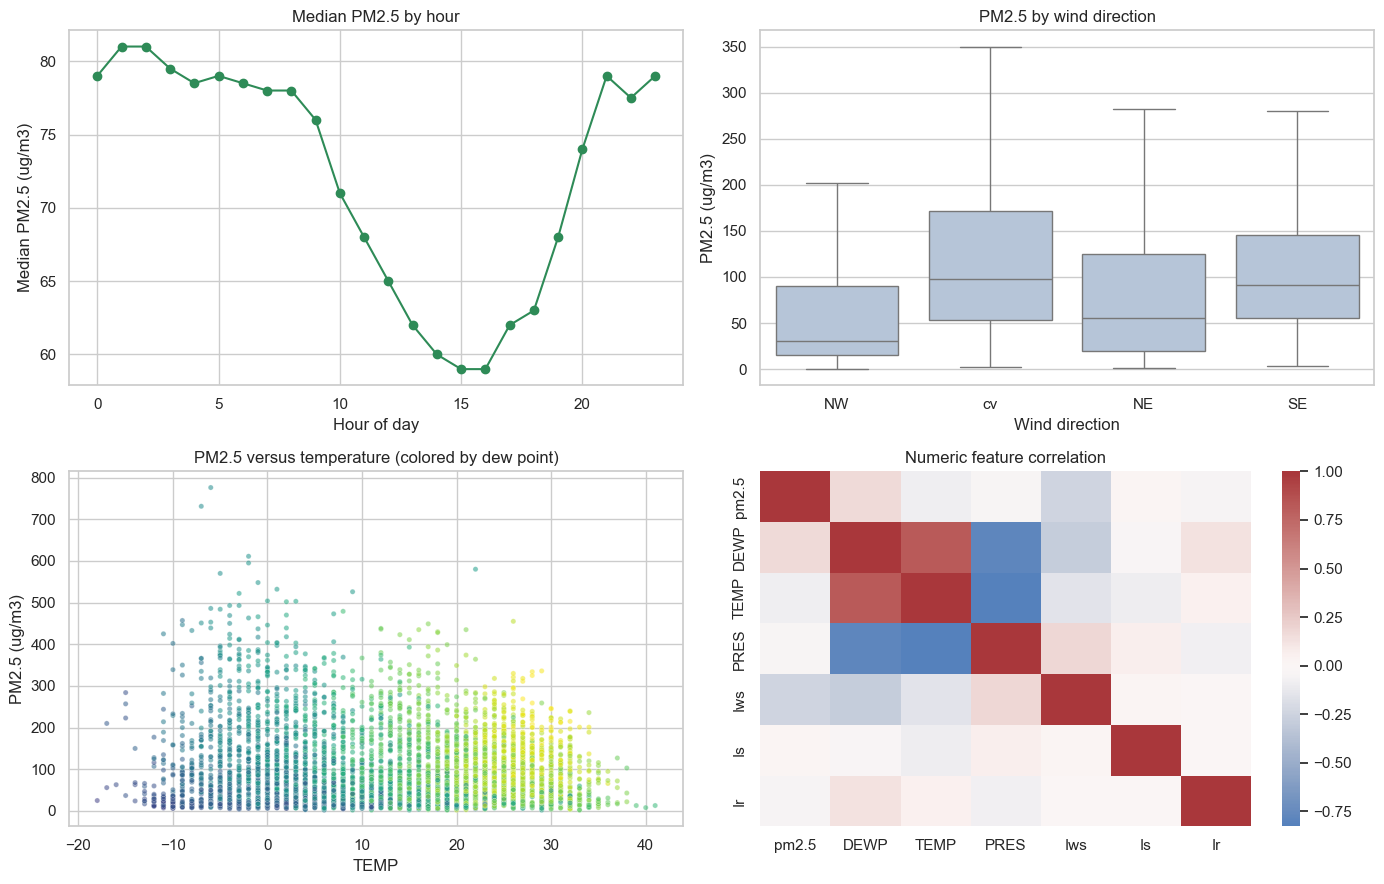

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Plot 5: daily cycle.
hourly = df.groupby(df.index.hour)["pm2.5"].median()
hourly.plot(ax=axes[0, 0], marker="o", color="seagreen")
axes[0, 0].set(title="Median PM2.5 by hour", xlabel="Hour of day", ylabel="Median PM2.5 (ug/m3)")

# Plot 6: distribution by wind direction.
sns.boxplot(data=df, x="cbwd", y="pm2.5", showfliers=False, ax=axes[0, 1], color="lightsteelblue")
axes[0, 1].set(title="PM2.5 by wind direction", xlabel="Wind direction", ylabel="PM2.5 (ug/m3)")

# Plot 7: weather relationship, with points sampled for readability.
scatter = df[["TEMP", "DEWP", "pm2.5"]].dropna().sample(n=min(5000, df[["TEMP", "DEWP", "pm2.5"]].dropna().shape[0]), random_state=RANDOM_STATE)
sns.scatterplot(data=scatter, x="TEMP", y="pm2.5", hue="DEWP", palette="viridis", s=14, alpha=0.55, ax=axes[1, 0], legend=False)
axes[1, 0].set(title="PM2.5 versus temperature (colored by dew point)", ylabel="PM2.5 (ug/m3)")

# Plot 8: correlation among numeric measurements.
correlation_columns = ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
sns.heatmap(df[correlation_columns].corr(), cmap="vlag", center=0, ax=axes[1, 1])
axes[1, 1].set(title="Numeric feature correlation")

plt.tight_layout()
plt.show()

For each of the four plots immediately above, write your own interpretation: what is measured, what pattern stands out, and one implication for the next modeling step. Treat correlations as associations, not proof of cause.

Before running this section, explain why calendar cycles and earlier PM2.5 readings can help predict the current hour. State explicitly that every PM2.5 lag is shifted backward in time, and that the chronological test period must not influence preprocessing or model fitting.

In [6]:
features = df[["DEWP", "TEMP", "PRES", "cbwd", "Iws", "Is", "Ir"]].copy()
features["hour_sin"] = np.sin(2 * np.pi * df.index.hour / 24)
features["hour_cos"] = np.cos(2 * np.pi * df.index.hour / 24)
features["month_sin"] = np.sin(2 * np.pi * df.index.month / 12)
features["month_cos"] = np.cos(2 * np.pi * df.index.month / 12)

# These predictor values come only from earlier recorded measurements.
observed_target = df["pm2.5_original"]
features["pm25_lag_1"] = observed_target.shift(1)
features["pm25_lag_24"] = observed_target.shift(24)
features["pm25_lag_168"] = observed_target.shift(168)
features["pm25_prior_24h_mean"] = observed_target.shift(1).rolling(24, min_periods=6).mean()

model_data = features.join(df["pm2.5"].rename("target")).dropna(subset=["target"])
cutoff_position = int(len(df) * 0.80)
cutoff_time = df.index[cutoff_position]
train_mask = model_data.index < cutoff_time
X_train, X_test = model_data.loc[train_mask, features.columns], model_data.loc[~train_mask, features.columns]
y_train, y_test = model_data.loc[train_mask, "target"], model_data.loc[~train_mask, "target"]

numeric_features = [column for column in features.columns if column != "cbwd"]
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
        ("wind", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), ["cbwd"]),
    ],
    remainder="drop",
)

print("Time cutoff:", cutoff_time)
print("Training rows:", len(X_train), "Testing rows:", len(X_test))
print("Feature columns:", list(features.columns))
print("Missing lag values are handled by training-fold imputers inside each model pipeline.")

Time cutoff: 2013-12-31 19:00:00
Training rows: 33419 Testing rows: 8724
Feature columns: ['DEWP', 'TEMP', 'PRES', 'cbwd', 'Iws', 'Is', 'Ir', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'pm25_lag_1', 'pm25_lag_24', 'pm25_lag_168', 'pm25_prior_24h_mean']
Missing lag values are handled by training-fold imputers inside each model pipeline.


Before fitting, explain why the previous-hour prediction is a meaningful baseline for a time series. Note why scaling belongs inside the pipeline for SVR, and why the SVR search uses only an early training subset with time-ordered cross-validation.

In [7]:
def regression_scores(actual, predicted):
    return {
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
        "R2": r2_score(actual, predicted),
    }

linear_model = Pipeline([("preprocess", preprocessor), ("model", LinearRegression())])
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

sample_size = min(2500, len(X_train))
X_tune = X_train.iloc[:sample_size]
y_tune = y_train.iloc[:sample_size]
svr_pipeline = Pipeline([("preprocess", preprocessor), ("model", SVR())])
svr_search = GridSearchCV(
    svr_pipeline,
    param_grid=[
        {"model__kernel": ["linear"], "model__C": [1, 10], "model__epsilon": [0.1, 1]},
        {"model__kernel": ["rbf"], "model__C": [1, 10], "model__epsilon": [0.1, 1], "model__gamma": ["scale", 0.1]},
    ],
    scoring="neg_root_mean_squared_error",
    cv=TimeSeriesSplit(n_splits=3),
    n_jobs=-1,
)
svr_search.fit(X_tune, y_tune)
svr_model = svr_search.best_estimator_
svr_predictions = svr_model.predict(X_test)

results = pd.DataFrame(
    {
        "Linear Regression": regression_scores(y_test, linear_predictions),
        "Tuned SVR": regression_scores(y_test, svr_predictions),
    }
).T

baseline_mask = X_test["pm25_lag_1"].notna()
baseline_scores = regression_scores(y_test.loc[baseline_mask], X_test.loc[baseline_mask, "pm25_lag_1"])
results.loc["Previous-hour baseline"] = baseline_scores
print("Tuning sample:", sample_size, "rows")
print("Best SVR parameters:", svr_search.best_params_)
display(results)

Tuning sample: 2500 rows
Best SVR parameters: {'model__C': 1, 'model__epsilon': 1, 'model__kernel': 'linear'}


,RMSE,MAE,R2
Linear Regression,22.604721,12.450867,0.941590
Tuned SVR,24.327053,14.744227,0.932350
Previous-hour baseline,22.017000,11.897202,0.944564


Before inspecting these diagnostics, write what a good residual pattern would look like. Then explain in your own words how each model performs on the full holdout and on the highest observed pollution hours, and whether the persistence baseline is difficult to beat.

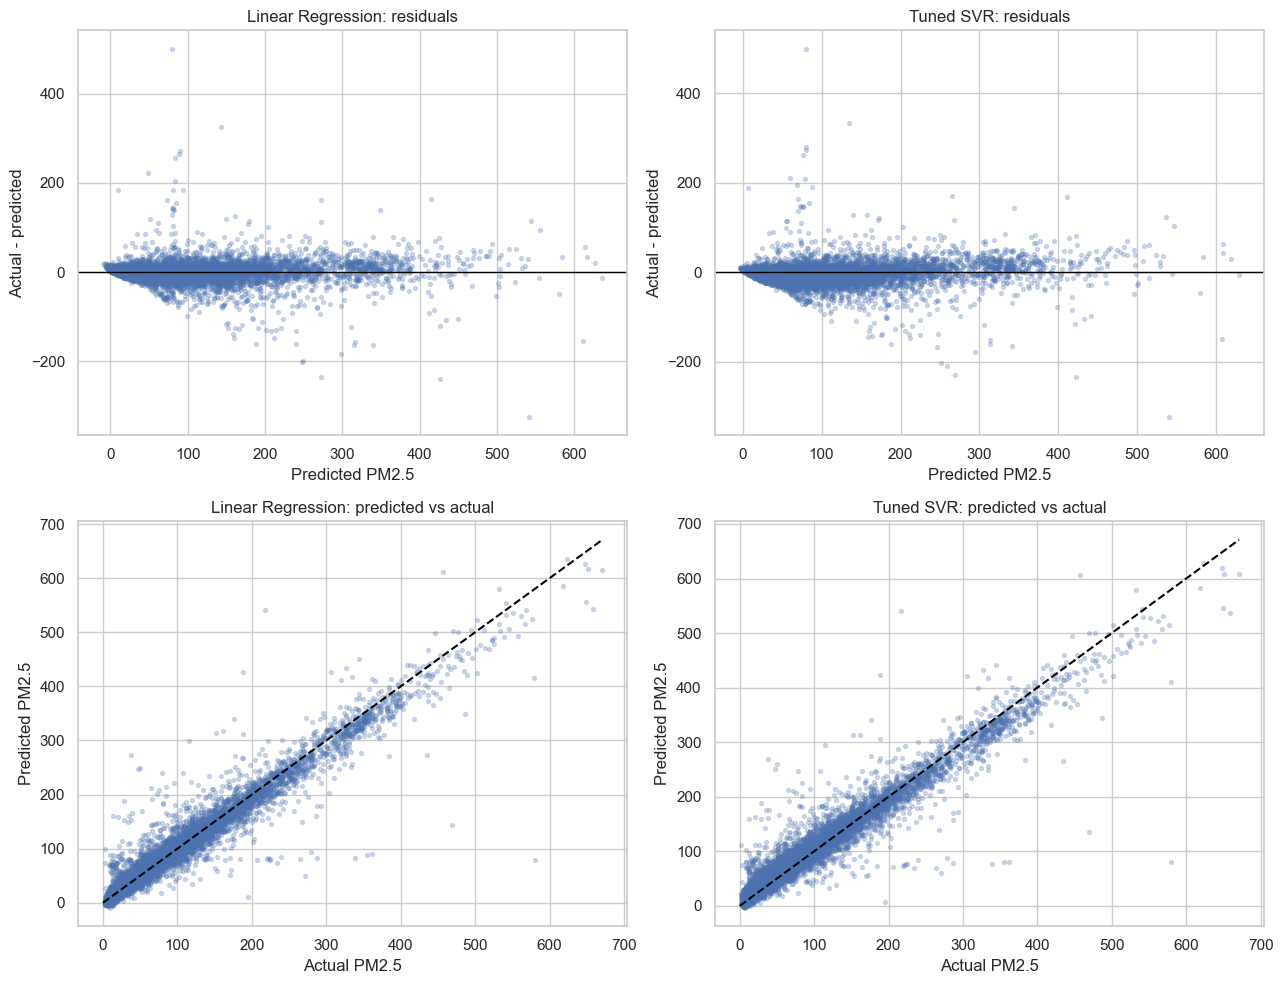

Linear train metrics: {'RMSE': np.float64(25.353184458817772), 'MAE': 13.664762248584104, 'R2': 0.9234928936853648}
SVR tuning-sample train metrics: {'RMSE': np.float64(37.51634849743698), 'MAE': 14.954400097247763, 'R2': 0.8215313502105509}


,actual,linear,svr
0,671.0,614.260073,608.576348
1,659.0,543.571562,536.008206
2,651.0,616.340441,608.032902
3,649.0,555.530500,546.151515
4,648.0,626.399476,618.370108
5,623.0,636.271307,628.665604
6,618.0,584.643254,583.346995
7,580.0,79.600933,79.952465
8,579.0,415.043925,410.377604
9,577.0,525.078753,515.081101


In [8]:
regression_predictions = {
    "Linear Regression": linear_predictions,
    "Tuned SVR": svr_predictions,
}
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for axis, (name, predicted) in zip(axes.flat[:2], regression_predictions.items()):
    residuals = y_test.to_numpy() - predicted
    axis.scatter(predicted, residuals, s=8, alpha=0.25)
    axis.axhline(0, color="black", linewidth=1)
    axis.set(title=f"{name}: residuals", xlabel="Predicted PM2.5", ylabel="Actual - predicted")

for axis, (name, predicted) in zip(axes.flat[2:], regression_predictions.items()):
    axis.scatter(y_test, predicted, s=8, alpha=0.25)
    axis.plot([0, y_test.max()], [0, y_test.max()], linestyle="--", color="black")
    axis.set(title=f"{name}: predicted vs actual", xlabel="Actual PM2.5", ylabel="Predicted PM2.5")

plt.tight_layout()
plt.show()

train_linear_scores = regression_scores(y_train, linear_model.predict(X_train))
train_svr_scores = regression_scores(y_train.iloc[:sample_size], svr_model.predict(X_train.iloc[:sample_size]))
print("Linear train metrics:", train_linear_scores)
print("SVR tuning-sample train metrics:", train_svr_scores)
extreme_positions = np.argsort(y_test.to_numpy())[-10:][::-1]
extreme_review = pd.DataFrame({"actual": y_test.iloc[extreme_positions].to_numpy(), "linear": linear_predictions[extreme_positions], "svr": svr_predictions[extreme_positions]})
display(extreme_review)

Before creating the labels, explain why the PM2.5 target itself is excluded from the predictors and why shifted past readings are allowed. After seeing the class counts, write why plain accuracy may hide poor performance on a smaller health-risk group.

,hours
target,
Good/Moderate,12221
Unhealthy for Sensitive Groups,5061
Unhealthy,15798
Very Unhealthy/Hazardous,9063


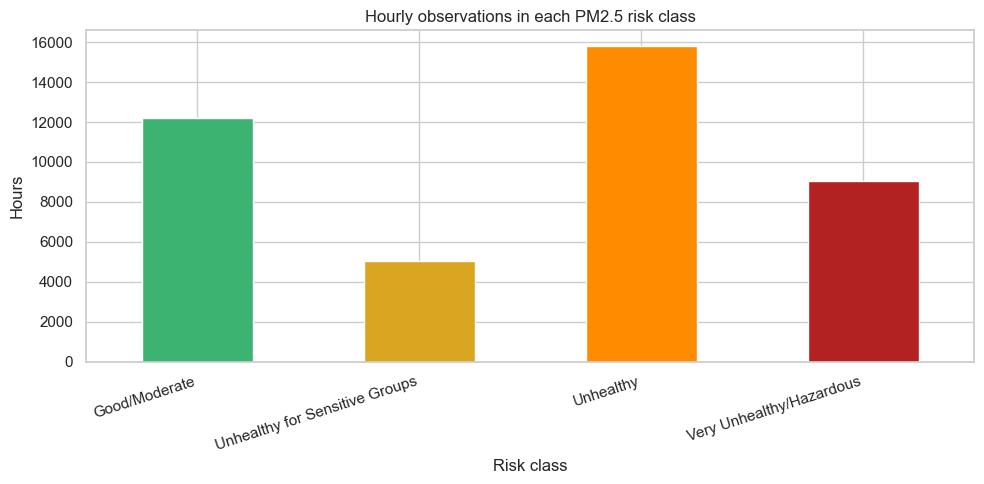

Predictor check: current PM2.5 is not a feature; all PM2.5 predictors are shifted past values.


In [9]:
CLASS_NAMES = [
    "Good/Moderate",
    "Unhealthy for Sensitive Groups",
    "Unhealthy",
    "Very Unhealthy/Hazardous",
]
class_bins = [-np.inf, 35.4, 55.4, 150.4, np.inf]
class_target = pd.cut(model_data["target"], bins=class_bins, labels=CLASS_NAMES)

class_counts = class_target.value_counts().reindex(CLASS_NAMES, fill_value=0)
display(class_counts.rename("hours").to_frame())
class_counts.plot(kind="bar", color=["mediumseagreen", "goldenrod", "darkorange", "firebrick"], figsize=(10, 5))
plt.title("Hourly observations in each PM2.5 risk class")
plt.xlabel("Risk class")
plt.ylabel("Hours")
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
plt.show()

y_train_class = class_target.loc[X_train.index]
y_test_class = class_target.loc[X_test.index]
print("Predictor check: current PM2.5 is not a feature; all PM2.5 predictors are shifted past values.")

Before fitting classifiers, explain why resampling must happen after each chronological training fold is formed and why it must never touch the holdout. Describe the trade-off you expect between detecting higher-risk classes and generating false alarms. SVC is computationally expensive, so the final SVC fits below use a class-stratified training-only subset; explain this limitation.

In [ ]:
classification_cv = TimeSeriesSplit(n_splits=3)

logistic_search = GridSearchCV(
    Pipeline([("preprocess", preprocessor), ("model", LogisticRegression(max_iter=2000, solver="lbfgs"))]),
    param_grid={"model__C": [0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    scoring="f1_macro",
    cv=classification_cv,
    n_jobs=-1,
)
logistic_search.fit(X_train, y_train_class)
best_logistic_c = logistic_search.best_params_["model__C"]

logistic_plain = Pipeline([("preprocess", preprocessor), ("model", LogisticRegression(C=best_logistic_c, max_iter=2000))])
logistic_balanced = Pipeline([("preprocess", preprocessor), ("model", LogisticRegression(C=best_logistic_c, class_weight="balanced", max_iter=2000))])
logistic_oversampled = ImbPipeline([
    ("preprocess", preprocessor),
    ("oversample", RandomOverSampler(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(C=best_logistic_c, max_iter=2000)),
])

classifier_tune_size = min(4000, len(X_train))
X_classifier_tune = X_train.iloc[:classifier_tune_size]
y_classifier_tune = y_train_class.iloc[:classifier_tune_size]
svc_models = {}
svc_searches = {}
for kernel in ["linear", "rbf"]:
    parameter_grid = {
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"],
    }
    if kernel == "rbf":
        parameter_grid["model__gamma"] = ["scale", 0.1]
    search = GridSearchCV(
        Pipeline([("preprocess", preprocessor), ("model", SVC(kernel=kernel, decision_function_shape="ovr"))]),
        param_grid=parameter_grid,
        scoring="f1_macro",
        cv=TimeSeriesSplit(n_splits=3),
        n_jobs=-1,
    )
    search.fit(X_classifier_tune, y_classifier_tune)
    best_parameters = {key.replace("model__", ""): value for key, value in search.best_params_.items()}
    svc_models[f"SVC {kernel}"] = Pipeline([
        ("preprocess", preprocessor),
        ("model", SVC(kernel=kernel, decision_function_shape="ovr", **best_parameters)),
    ])
    svc_searches[kernel] = search.best_params_

# Limit quadratic-cost SVC fitting while preserving each class in the training subset.
svc_rows_per_class = min(2000, max(1, len(X_train) // len(CLASS_NAMES)))
svc_train_indices = pd.Index([])
for label in CLASS_NAMES:
    class_indices = y_train_class.index[y_train_class == label]
    sampled = X_train.loc[class_indices].sample(n=min(len(class_indices), svc_rows_per_class), random_state=RANDOM_STATE)
    svc_train_indices = svc_train_indices.append(sampled.index)
X_svc_train = X_train.loc[svc_train_indices].sort_index()
y_svc_train = y_train_class.loc[X_svc_train.index]

classifiers = {
    "Logistic Regression": logistic_plain,
    "Logistic Regression (balanced weights)": logistic_balanced,
    "Logistic Regression (random oversampling)": logistic_oversampled,
    **svc_models,
}
for name, classifier in classifiers.items():
    if name.startswith("SVC"):
        classifier.fit(X_svc_train, y_svc_train)
    else:
        classifier.fit(X_train, y_train_class)

print("Best Logistic Regression parameters:", logistic_search.best_params_)
print("Linear SVC tuning:", svc_searches["linear"])
print("RBF SVC tuning:", svc_searches["rbf"])
print("SVC tuning sample:", classifier_tune_size, "chronologically earliest training rows")
print("SVC final-fit sample:", len(X_svc_train), "stratified training-only rows")